# VaR of Equity Portfolio

### Data
This problem uses `weekly` return data from `data/spx_returns_weekly.xlsx`.

Choose any `4` stocks to evaluate below. We use **AAPL, META, NVDA and TSLA**.

In [ ]:
import pandas as pd
import numpy as np
from IPython.display import display


SPX_FILE = 'FINM Portfolio/spx_returns_weekly.xlsx'
STOCKS = ['AAPL', 'META', 'NVDA', 'TSLA']

#Weekly returns of the four chosen stocks
stock_rets = pd.read_excel(SPX_FILE, sheet_name = 'spx returns', index_col = 0, parse_dates=True)[STOCKS]

#Annualization factor for weekly data
ANN_W = 52

print(f"Sample: {stock_rets.index.min():%Y-%m-%d} to {stock_rets.index.max():%Y-%m-%d} ({len(stock_rets)} weeks)")
stock_rets.head()

# 1 Diversification

### 1.1
Using the full sample, calculate for each series the (unconditional)
* volatility
* empirical VaR (.05)
* empirical CVaR (.05)

Recall that by **empirical** we refer to the direct quantile estimation. (For example, using `.quantile()` in pandas.

In [ ]:
ALPHA = 0.05

#Empirical VaR: the 5th percentile of weekly returns, i.e. the return we fall below only 5% of the time
VaR = stock_rets.quantile(ALPHA)

risk_stats = pd.DataFrame({
    'Vol (weekly)': stock_rets.std(),
    'Vol (annualized)': stock_rets.std() * np.sqrt(ANN_W),
    'VaR (0.05)': VaR,
    'CVaR (0.05)': stock_rets[stock_rets <= VaR].mean(), # CVaR: the average return in the worst 5% of weeks (those at or below the VaR)
})

risk_stats.style.format('{:.2%}')

### 1.2
Form an equally-weighted portfolio of the investments.

Calculate the statistics of `1.1` for this portfolio, and compare the results to the individual return statistics. What do you find? What is driving this result?

In [19]:
def tail_risk(r, alpha = 0.05, ann = 52):
    '''
    Same statistics as 1.1 for a single return series:
    volatility (weekly and annualized), empirical VaR and CVaR
    '''
    VaR = r.quantile(alpha)

    return pd.Series({
        'Vol (weekly)': r.std(),
        'Vol (annualized)': r.std() * np.sqrt(ann),
        'VaR (0.05)': VaR,
        'CVaR (0.05)': r[r <= VaR].mean(),
    })


#Equally-weighted portfolio: 25% in each stock, rebalanced every week
w_ew = pd.Series(1 / len(STOCKS), index = STOCKS)
port_ew = stock_rets @ w_ew

#Compare the portfolio to each stock, and to the simple average of the individual stats
compare_ew = risk_stats.copy()
compare_ew.loc['Average of the 4 stocks'] = risk_stats.mean()
compare_ew.loc['EW portfolio'] = tail_risk(port_ew, ALPHA, ANN_W)

display(compare_ew.style.format('{:.2%}'))

#Correlation between the stocks, the driver of the result
display(stock_rets.corr().round(2))

,Vol (weekly),Vol (annualized),VaR (0.05),CVaR (0.05)
AAPL,3.85%,27.76%,-5.49%,-8.30%
META,4.96%,35.75%,-7.23%,-10.64%
NVDA,6.30%,45.44%,-8.58%,-11.53%
TSLA,8.04%,57.97%,-11.70%,-14.78%
Average of the 4 stocks,5.79%,41.73%,-8.25%,-11.31%
EW portfolio,4.33%,31.20%,-6.07%,-8.42%


,AAPL,META,NVDA,TSLA
AAPL,1.00,0.41,0.48,0.44
META,0.41,1.00,0.43,0.26
NVDA,0.48,0.43,1.00,0.41
TSLA,0.44,0.26,0.41,1.00


- The equally-weighted portfolio has a weekly volatility of about 4.3%, VaR of about −6.1% and CVaR of about −8.4%.
- That is less risky than the average stock (vol 5.8%, VaR −8.3%, CVaR −11.4%), and only slightly riskier than AAPL, the safest stock on its own.

**What is driving this** Diversification. The stocks are only moderately correlated with each other (correlations between about 0.26 and 0.48). The lower the correlations, the more of the individual risk cancels out.

### 1.3
Re-calculate `1.2`, but this time drop your most volatile asset, and replace the portion it was getting with 0. (You could imagine we're replacing the most volatile asset with a negligibly small risk-free rate.)

In comparing the answer here to 1.2, how much risk is your most volatile asset adding to the portfolio? Is this in line with the amount of risk we measured in the stand-alone risk-assessment of `1.1`?

In [ ]:
#Most volatile stock from 1.1
most_volatile = risk_stats['Vol (weekly)'].idxmax()
print(f"Most volatile asset: {most_volatile}")

#Same 25% weights, but the most volatile stock gets 0 (its 25% sits in a ~0 risk-free rate)
w_drop = w_ew.copy()
w_drop[most_volatile] = 0
port_drop = stock_rets @ w_drop

compare_drop = pd.DataFrame({
    'EW portfolio (1.2)': tail_risk(port_ew, ALPHA, ANN_W),
    f'Without {most_volatile}': tail_risk(port_drop, ALPHA, ANN_W),
}).T
compare_drop.loc[f'Risk added by {most_volatile}'] = compare_drop.iloc[0] - compare_drop.iloc[1]
compare_drop.loc[f'{most_volatile} stand-alone (1.1)'] = risk_stats.loc[most_volatile]
compare_drop.loc[f'{most_volatile} stand-alone x 25% weight'] = risk_stats.loc[most_volatile] * w_ew[most_volatile]

display(compare_drop.style.format('{:.2%}'))

#Share of the EW portfolio's variance that comes from each stock: w_i * (Cov w)_i / (w' Cov w)
cov = stock_rets.cov()
var_contrib = w_ew * (cov @ w_ew) / (w_ew @ cov @ w_ew)
display(var_contrib.to_frame('Share of portfolio variance').style.format('{:.1%}'))

- Taking TSLA out lowers risk, but not by much. Weekly vol falls from 4.3% to 3.0%, so TSLA adds about 1.3%. 
- On its own, TSLA looked far riskier. Its stand-alone vol is 8.0%, and even a quarter of that is more than the 1.3% it actually adds.

it is not in line with 1.1. TSLA doesn't always move with the other stocks, so part of its swings cancel out inside the portfolio. 

# 2 Conditional Risk

### 2.1
Let's measure the **conditional** statistics of the equally-weighted portfolio of `1.2`, as of the end of the sample.

#### Volatility
For each security, calculate the **rolling** volatility series, $\sigma_t$, with a window of $m = 26$.

The value at $\sigma_t$ in the notes denotes the estimate using data through time $t-1$, and thus (potentially) predicting the volatility at $\sigma_t$.

#### Mean
Suppose we can approximate that the weekly mean return is zero.

#### VaR
Calculate the **normal VaR** and **normal CVaR** for $q = .05$ and $\tau = 1$ as of the end of the sample. Use the approximation, $\mathrm{z}_{.05} = -1.65$.

#### Notation Note
In this setup, we are using a forecasted volatility, $\sigma_t$ to estimate the VaR return we would have estimated at the end of $t-1$ in prediction of time $t$.

#### Conclude and Compare
Report
* volatility (annualized).
* normal VaR (.05)
* normal CVaR (.05)

How do these compare to the answers in `1.2`?

In [21]:
import matplotlib.pyplot as plt
from scipy.stats import norm

WINDOW = 26
Z_05 = -1.65

#Each stock plus the equally-weighted portfolio from 1.2
cond_rets = stock_rets.copy()
cond_rets['EW portfolio'] = port_ew

#Rolling volatility with a zero mean: sigma_t^2 = (1/m) * sum of the last m squared returns
#.shift(1) so that sigma_t only uses data through t-1, i.e. it is a forecast of week t
rolling_vol = np.sqrt((cond_rets ** 2).rolling(WINDOW).mean()).shift(1)

#Value as of the end of the sample
sigma_end = rolling_vol.iloc[-1]

#Normal VaR and CVaR with mean zero and tau = 1 week:
#VaR  = z * sigma
#CVaR = -(pdf(z) / q) * sigma, the average return below the VaR if returns are normal
cond_stats = pd.DataFrame({
    'Vol (annualized)': sigma_end * np.sqrt(ANN_W),
    'Normal VaR (0.05)': Z_05 * sigma_end,
    'Normal CVaR (0.05)': -(norm.pdf(Z_05) / ALPHA) * sigma_end,
})

print(f"Conditional estimates for the week of {rolling_vol.index[-1]:%Y-%m-%d}, using the {WINDOW} weeks before it")
display(cond_stats.style.format('{:.2%}'))

Conditional estimates for the week of 2026-06-26, using the 26 weeks before it


,Vol (annualized),Normal VaR (0.05),Normal CVaR (0.05)
AAPL,24.62%,-5.63%,-6.98%
META,40.72%,-9.32%,-11.55%
NVDA,29.09%,-6.66%,-8.25%
TSLA,36.57%,-8.37%,-10.37%
EW portfolio,22.85%,-5.23%,-6.48%


,"Unconditional, empirical (1.2)","Conditional, normal (2.1)"
Vol (annualized),31.20%,22.85%
VaR (0.05),-6.07%,-5.23%
CVaR (0.05),-8.42%,-6.48%


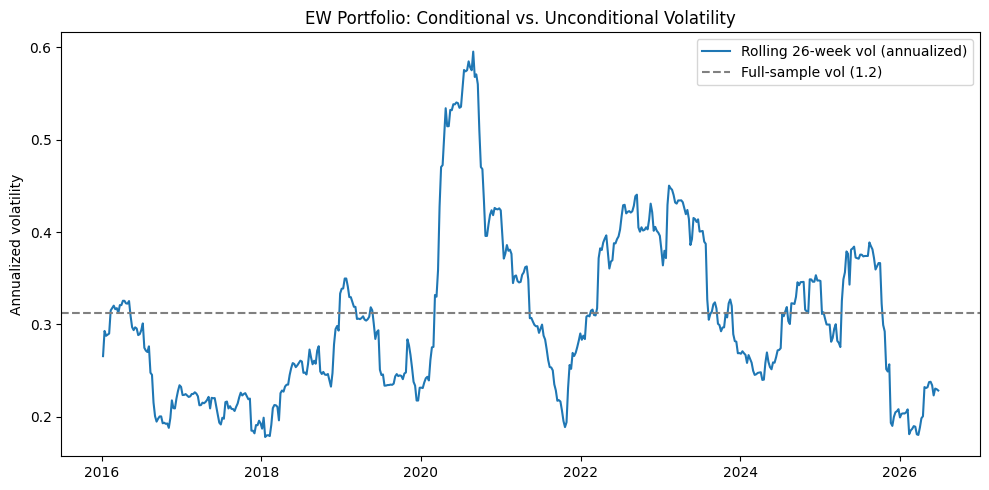

In [22]:
#Compare the conditional (end of sample) estimates for the EW portfolio to the unconditional full-sample ones from 1.2
uncond_ew = tail_risk(port_ew, ALPHA, ANN_W)

compare_cond = pd.DataFrame({
    'Unconditional, empirical (1.2)': [uncond_ew['Vol (annualized)'], uncond_ew['VaR (0.05)'], uncond_ew['CVaR (0.05)']],
    'Conditional, normal (2.1)': cond_stats.loc['EW portfolio'].values,
}, index = ['Vol (annualized)', 'VaR (0.05)', 'CVaR (0.05)'])

display(compare_cond.style.format('{:.2%}'))

#Rolling volatility of the EW portfolio over time, against its full-sample volatility
plt.figure(figsize = (10, 5))
plt.plot(rolling_vol['EW portfolio'] * np.sqrt(ANN_W), label = f'Rolling {WINDOW}-week vol (annualized)', linewidth = 1.5)
plt.axhline(uncond_ew['Vol (annualized)'], color = 'grey', linestyle = '--', label = 'Full-sample vol (1.2)')
plt.title('EW Portfolio: Conditional vs. Unconditional Volatility')
plt.ylabel('Annualized volatility')
plt.legend()
plt.tight_layout()
plt.show()

| EW portfolio | 1.2 (full sample) | 2.1 (last 26 weeks) |
|---|---|---|
| Vol (annualized) | 31.2% | 22.9% |
| VaR (0.05) | −6.1% | −5.2% |
| CVaR (0.05) | −8.4% | −6.5% |

All lower in 2.1. The last 26 weeks were calmer than average, so the forecast for next week's risk is lower. 1.2 averages over calm and crisis periods; 2.1 reflects only recent conditions.

### 2.2
Backtest the VaR using the **hit test**. Namely, check how many times the realized return at $t$ was smaller than the VaR return calculated using $\sigma_t$, (where again remember the notation in the notes uses $\sigma_t$ as a vol based on data through $t-1$.)

Report the percentage of "hits" using both the
* expanding volatility
* rolling volatility

In [24]:
#Expanding volatility: same zero-mean formula as the rolling one, but using ALL past weeks instead of the last 26
#min_periods = WINDOW so both methods start on the same week; .shift(1) so sigma_t only uses data through t-1
expanding_vol = np.sqrt((cond_rets ** 2).expanding(min_periods = WINDOW).mean()).shift(1)

def hit_rate(rets, vol, z = -1.65):
    '''
    Hit test: a "hit" is a week where the realized return fell below the VaR forecast for that week
    VaR_t = z * sigma_t, with sigma_t estimated from data through t-1
    '''
    VaR = z * vol
    valid = VaR.notna() # skip the first weeks where there is not enough data for a forecast
    hits = (rets < VaR) & valid

    return hits.sum() / valid.sum()


hit_test = pd.DataFrame({
    'Expanding vol': hit_rate(cond_rets, expanding_vol, Z_05),
    'Rolling vol (26 weeks)': hit_rate(cond_rets, rolling_vol, Z_05),
})

print(f"Backtest: {expanding_vol.dropna().index.min():%Y-%m-%d} to {cond_rets.index.max():%Y-%m-%d} ({expanding_vol['EW portfolio'].notna().sum()} weeks). Target hit rate = 5%")
display(hit_test.style.format('{:.2%}'))

Backtest: 2016-01-08 to 2026-06-26 (547 weeks). Target hit rate = 5%


,Expanding vol,Rolling vol (26 weeks)
AAPL,3.66%,4.39%
META,4.75%,4.57%
NVDA,2.74%,4.02%
TSLA,4.75%,4.75%
EW portfolio,4.02%,3.84%


***

# Private Equity

### Data
* Use the data in `../data/private_equity_data.xlsx`.

The returns are **weekly**, so we annualize the mean with a scaling of 52 and the volatility with a scaling of $\sqrt{52}$. We use **excess** returns (over `SHV`) throughout, so that the Sharpe ratio and alpha are measured relative to the risk-free rate.

In [11]:
import statsmodels.api as sm

PE_FILE = 'FINM Portfolio/private_equity_data.xlsx'

#Info sheet describing each ticker
pe_info = pd.read_excel(PE_FILE, sheet_name = 'descriptions', index_col = 0)

#Excess returns (weekly), SHV has already been subtracted
pe_excess = pd.read_excel(PE_FILE, sheet_name = 'excess returns', index_col = 0, parse_dates=True)

#Annualization factor for weekly data
ANN_W = 52

print(f"Sample: {pe_excess.index.min():%Y-%m-%d} to {pe_excess.index.max():%Y-%m-%d} ({len(pe_excess)} weeks)")
display(pe_info[['shortName']])

Sample: 2015-01-09 to 2025-10-03 (561 weeks)


,shortName
ticker,
SPY,SPDR S&P 500
VTV,Vanguard Value ETF
AGG,iShares Core U.S. Aggregate Bon
HYG,iShares iBoxx $ High Yield Corp
IEF,iShares 7-10 Year Treasury Bond
PSP,Invesco Global Listed Private E
PEX,ProShares Global Listed Private
APO,"Apollo Global Management, Inc."
BX,Blackstone Inc.


# 1. Performance
Calculate performance stats for the assets, both stand-alone (mean, vol, Sharpe) as well as linear decompositions (alpha, beta, info ratio, r-squared).

In [12]:
#Stand-alone performance
pe_summary = pd.DataFrame({
    'Mean': pe_excess.mean() * ANN_W,
    'Vol': pe_excess.std() * np.sqrt(ANN_W),
})
pe_summary['Sharpe'] = pe_summary['Mean'] / pe_summary['Vol']

pe_summary.sort_values('Sharpe', ascending = False).style.format({'Mean': '{:.2%}', 'Vol': '{:.2%}', 'Sharpe': '{:.2f}'})

,Mean,Vol,Sharpe
SPY,12.31%,16.97%,0.73
APO,23.15%,36.79%,0.63
KKR,22.86%,36.50%,0.63
BX,21.76%,35.82%,0.61
VTV,8.65%,16.41%,0.53
CG,14.45%,36.71%,0.39
PSP,4.94%,23.17%,0.21
HYG,-0.47%,9.54%,-0.05
PEX,-1.43%,21.46%,-0.07
IEF,-0.73%,6.44%,-0.11


In [15]:
def regress_on_market(y, x, ann = 52):
    '''
    Regression with intercept: y = alpha + beta * x + error
    Dependent Variable Y is the asset's excess returns
    Independent Variable X is SPY excess returns
    '''

    X = sm.add_constant(x.rename('SPY')) # add a column of 1s to account for the alpha or the intercept
    results = sm.OLS(y, X, missing = 'drop').fit() # fit OLS model
    alpha, beta = results.params['const'], results.params['SPY']

    return pd.Series({
        'Alpha (annualized)': alpha * ann,
        'Market Beta': beta, # not annualized, the scaling cancels out
        'Information Ratio': alpha * ann / (results.resid.std() * np.sqrt(ann)), # alpha divided by the volatility of the residuals (tracking error)
        'R-squared': results.rsquared,
    })

#Linear decomposition of every asset on SPY (SPY on itself is trivial, so drop it)
pe_decomp = pe_excess.drop(columns = 'SPY').apply(lambda y: regress_on_market(y, pe_excess['SPY'], ann = ANN_W)).T

pe_decomp.style.format({'Alpha (annualized)': '{:.2%}', 'Market Beta': '{:.2f}', 'Information Ratio': '{:.2f}', 'R-squared': '{:.2f}'})

,Alpha (annualized),Market Beta,Information Ratio,R-squared
VTV,-2.39%,0.90,-0.39,0.86
AGG,-1.60%,0.07,-0.32,0.05
HYG,-5.70%,0.42,-0.91,0.57
IEF,-0.40%,-0.03,-0.06,0.01
PSP,-9.60%,1.18,-0.83,0.75
PEX,-13.46%,0.98,-0.99,0.60
APO,4.93%,1.48,0.18,0.47
BX,3.74%,1.46,0.14,0.48
KKR,3.48%,1.57,0.14,0.54
CG,-3.59%,1.47,-0.13,0.46


# 2. Replication
Can we replicate private equity `APO` using the following?
* public equity `SPY`
* treasury bonds `IEF`
* high-yield corp bonds `HYG`

How does that compare to `APO` against `SPY` alone?

In [16]:
def replicate(y, X, ann = 52):
    '''
    Replication regression: y = alpha + beta' X + error
    Dependent Variable Y is APO excess returns
    Independent Variables X are the ETFs used to replicate it
    '''

    results = sm.OLS(y, sm.add_constant(X), missing = 'drop').fit() # add a column of 1s to account for the alpha or the intercept

    out = pd.concat([
        pd.Series({'Alpha (annualized)': results.params['const'] * ann}),
        results.params.drop('const').add_prefix('Beta '),
        results.tvalues.rename({'const': 'alpha'}).add_prefix('t-stat '),
    ])
    out['R-squared'] = results.rsquared
    out['Tracking Error (annualized)'] = results.resid.std() * np.sqrt(ann) # volatility of the part we cannot replicate

    return out


apo = pe_excess['APO']

rep_spy = replicate(apo, pe_excess[['SPY']], ann = ANN_W)
rep_3 = replicate(apo, pe_excess[['SPY', 'IEF', 'HYG']], ann = ANN_W)

#Side-by-side comparison, keeping the row order of the bigger model
apo_replication = pd.DataFrame({'SPY only': rep_spy, 'SPY + IEF + HYG': rep_3}).reindex(rep_3.index)

display(apo_replication.style.format('{:.4f}', na_rep = '-'))

print(f"APO volatility (annualized): {apo.std() * np.sqrt(ANN_W):.2%}")
print('Correlation of the replicating assets:')
display(pe_excess[['SPY', 'IEF', 'HYG']].corr().round(2))

,SPY only,SPY + IEF + HYG
Alpha (annualized),0.0493,0.0996
Beta SPY,1.4802,1.0660
Beta IEF,-,-0.7040
Beta HYG,-,0.9310
t-stat alpha,0.5992,1.2335
t-stat SPY,22.0864,10.4291
t-stat IEF,-,-3.9565
t-stat HYG,-,5.1056
R-squared,0.4660,0.4965
Tracking Error (annualized),0.2688,0.2611


APO volatility (annualized): 36.79%
Correlation of the replicating assets:


,SPY,IEF,HYG
SPY,1.00,-0.07,0.75
IEF,-0.07,1.00,0.11
HYG,0.75,0.11,1.00


**Can we replicate APO with SPY, IEF and HYG?** Not well.
- The betas are **SPY 1.07, IEF −0.70, HYG 0.93**, all significant (|t| > 2).
- R-squared is only 0.50, so half of APO's movement can't be explained by these ETFs.

**Compared with SPY alone**
- SPY alone already gets an R-squared of 0.47. Adding IEF and HYG only raises it by 3 percentage points.
- The SPY beta falls from 1.48 to 1.07 because SPY and HYG are correlated (0.75), so some of the "equity" exposure is credit exposure picked up by HYG.

SPY does most of the work, and the bond ETFs add very little. APO has a large part that public market returns can't replicate.